# C03 — Modelos de tipo corto, Hull-White, árbol trinomial y swaps cancelables

**Objetivos:** entender Vasicek y por qué no basta; Hull-White analítico (opciones sobre bonos, swaptions);
calibración a swaptions; árbol trinomial ajustado a la curva; valorar una bermuda; caso del préstamo
prepagable con swap cancelable.

**Fuentes:** Hull cap. 31 (31.2, 31.3, 31.4, 31.7 y 31.8) y cap. 32; Veronesi cap. 14, 15 y 19. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from scipy.optimize import brentq
from derivlab.market import sample_market
from derivlab.curves import build_curves, discount_t
from derivlab.scenarios import HullWhite, pathwise_discount
from derivlab.short_rate import (vasicek_zero_rate, hw_zcb_option, forward_swap_today, swap_legs_at, hw_swaption,
                                 hw_implied_normal_vol, calibrate_hw, HWTree, swap_value_today)
from derivlab.vol_market import SWAPTION_EXPIRIES, SWAPTION_TENORS, SWAPTION_ATM_NORMAL_VOLS, swaption_vol

m = sample_market()
estr, eur = build_curves(m)

## 1. Vasicek: un modelo de equilibrio

$dr = a(b - r)\,dt + \sigma\,dW$. Con tres parámetros produce curvas crecientes, planas, invertidas o con joroba,
pero no puede reproducir la curva de hoy. Hull-White añade una función del tiempo para ajustarla exactamente.

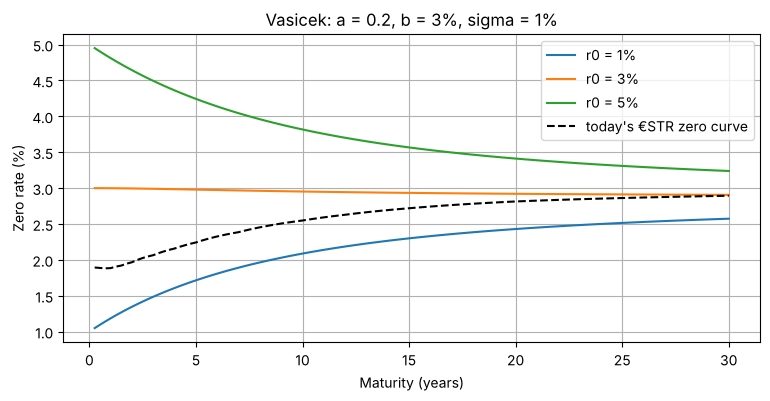

CASE Vasicek long rate with b = 3%: 2.830% (b - sigma^2 / (2 a^2) = 2.875%)


In [2]:
T = np.linspace(0.25, 30, 120)
for r0 in [0.010, 0.030, 0.050]:
    plt.plot(T, vasicek_zero_rate(r0, 0.2, 0.03, 0.01, T) * 100, label=f"r0 = {r0:.0%}")
plt.plot(T, [-np.log(discount_t(estr, t)) / t * 100 for t in T], "k--", label="today's €STR zero curve")
plt.xlabel("Maturity (years)"); plt.ylabel("Zero rate (%)"); plt.title("Vasicek: a = 0.2, b = 3%, sigma = 1%")
plt.legend(); plt.show()
long_rate = vasicek_zero_rate(0.01, 0.2, 0.03, 0.01, 200.0)
print(f"CASE Vasicek long rate with b = 3%: {long_rate:.3%} (b - sigma^2 / (2 a^2) = {0.03 - 0.01 ** 2 / (2 * 0.2 ** 2):.3%})")

## 2. Hull-White: opciones sobre bonos y swaptions analíticas

Opción sobre un bono cupón cero (Hull ec. 31.20):
$\text{call} = P(0,s)N(h) - K P(0,T) N(h - \sigma_P)$, con
$\sigma_P = \frac{\sigma}{a}\left(1-e^{-a(s-T)}\right)\sqrt{\frac{1-e^{-2aT}}{2a}}$.
Una swaption es una opción sobre un bono con cupón; aquí se integra sobre el factor del modelo en la medida
forward del vencimiento (equivalente a la descomposición de Jamshidian que describe Hull en 31.4).

In [3]:
hw0 = HullWhite(estr, eur, a=0.03, sigma=0.0085)
times = np.array([0.0, 2.0])
x = hw0.simulate(times, 200000, seed=21)
D = pathwise_discount(estr, hw0.a, hw0.sigma, times, x)[:, 1]
K = 0.9
mc = (D * np.maximum(hw0.P(2.0, 7.0, x[:, 1]) - K, 0)).mean()
print(f"CASE call on 7y zero bond, expiry 2y, strike 0.90: formula {hw_zcb_option(hw0, 2.0, 7.0, K):.5f}, Monte Carlo {mc:.5f}")

CASE call on 7y zero bond, expiry 2y, strike 0.90: formula 0.01049, Monte Carlo 0.01047


## 3. Calibración: lo que un factor puede y no puede reproducir

Con a = 0,03 y σ = 0,85 % (los parámetros de la Parte B) se calculan las volatilidades normales que implica el
modelo y se comparan con la matriz de mercado. Después se calibran a y σ a toda la matriz.

In [4]:
model = np.array([[hw_implied_normal_vol(hw0, e, t) for t in SWAPTION_TENORS] for e in SWAPTION_EXPIRIES])
diff = pd.DataFrame((model - SWAPTION_ATM_NORMAL_VOLS) * 1e4, index=[f"{e}y" for e in SWAPTION_EXPIRIES],
                    columns=[f"{t}y" for t in SWAPTION_TENORS])
print("Model - market (bp), a = 0.03, sigma = 0.85%")
print(diff.round(1))
inst_all = [(e, t, SWAPTION_ATM_NORMAL_VOLS[i, j]) for i, e in enumerate(SWAPTION_EXPIRIES)
            for j, t in enumerate(SWAPTION_TENORS) if e + t <= 30]
hw_all, rows_all = calibrate_hw(estr, eur, inst_all)
err_all = np.array([(r["model_vol"] - r["market_vol"]) * 1e4 for r in rows_all])
print(f"CASE full-matrix calibration: a = {hw_all.a:.4f}, sigma = {hw_all.sigma:.4%}; RMSE {np.sqrt((err_all ** 2).mean()):.1f} bp, "
      f"worst {np.abs(err_all).max():.1f} bp")

Model - market (bp), a = 0.03, sigma = 0.85%
      1y   2y   5y  10y   20y
1y   6.3  3.1 -2.4 -5.8  -9.4
2y   1.2 -1.0 -5.4 -7.7 -11.1
3y  -1.8 -3.0 -6.4 -8.6 -11.8
5y  -3.0 -4.1 -6.4 -8.4 -11.4
7y  -2.1 -3.2 -5.4 -7.3 -11.0
10y -1.1 -2.2 -4.3 -5.9  -9.3


CASE full-matrix calibration: a = 0.0131, sigma = 0.8276%; RMSE 2.3 bp, worst 5.5 bp


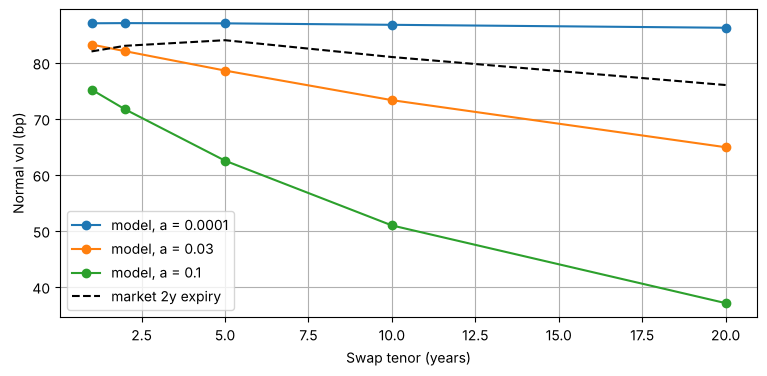

In [5]:
for a_ in [0.0001, 0.03, 0.10]:
    h = HullWhite(estr, eur, a=a_, sigma=0.0085)
    plt.plot(SWAPTION_TENORS, [hw_implied_normal_vol(h, 2, t) * 1e4 for t in SWAPTION_TENORS], "o-", label=f"model, a = {a_}")
plt.plot(SWAPTION_TENORS, SWAPTION_ATM_NORMAL_VOLS[1] * 1e4, "k--", label="market 2y expiry")
plt.xlabel("Swap tenor (years)"); plt.ylabel("Normal vol (bp)"); plt.legend(); plt.show()

La reversión a la media controla cuánto cae la volatilidad con el plazo del swap: con a alta, los tipos largos se
mueven mucho menos que los cortos. Un factor no puede reproducir toda la matriz. La práctica es calibrar solo
a las swaptions que importan para el producto: para una bermuda, las **co-terminales** (todas acaban en la misma
fecha).

## 4. Árbol trinomial (Hull 31.7)

Primera etapa: un árbol para x con saltos Δx = σ√(3Δt), ramificación normal en el centro y hacia dentro en los
extremos (j_max). Segunda etapa: se desplaza cada paso con α_m para reproducir la curva de descuento usando
precios de Arrow-Debreu.

In [6]:
co = [(e, 10 - e, swaption_vol(e, 10 - e)) for e in range(3, 10)]
hw_c, rows_c = calibrate_hw(estr, eur, co, a=0.03)
cal = pd.DataFrame(rows_c)
cal["error_bp"] = (cal.model_vol - cal.market_vol) * 1e4
print(f"Co-terminal calibration (a fixed at 0.03): sigma = {hw_c.sigma:.4%}")
print(cal.assign(market_vol=cal.market_vol * 1e4, model_vol=cal.model_vol * 1e4).round(2).to_string(index=False))
print(f"CASE constant sigma leaves co-terminal errors from {cal.error_bp.min():.1f} to {cal.error_bp.max():+.1f} bp; "
      "freeing a does not help, a piecewise sigma(t) would fit them exactly")
tree = HWTree(hw_c, 9.0, 1 / 12)
vals = np.ones(2 * tree.jmax + 1)
for k in range(tree.n - 1, -1, -1):
    vals = tree.step_back(k, vals)
F37, A37 = forward_swap_today(hw_c, 3, 7)
eu_tree = tree.european_swaption(3.0, 10.0, F37, payer=False)
eu_an = hw_swaption(hw_c, 3, 7, F37, payer=False)
print(f"CASE tree: {tree.n} steps, jmax = {tree.jmax}; P(0,9) tree {vals[tree.jmax]:.6f} vs curve {discount_t(estr, 9.0):.6f}")
print(f"CASE European receiver 3y7y ATM: tree {eu_tree:.5f}, analytic {eu_an:.5f} ({eu_tree / eu_an - 1:+.2%})")

Co-terminal calibration (a fixed at 0.03): sigma = 0.9039%
 expiry  tenor  market_vol  model_vol  error_bp
      3      7       82.80      80.19     -2.61
      4      6       82.40      80.26     -2.14
      5      5       82.00      80.34     -1.66
      6      4       80.83      80.41     -0.42
      7      3       79.67      80.50      0.83
      8      2       78.67      80.59      1.92
      9      1       77.33      80.69      3.36
CASE constant sigma leaves co-terminal errors from -2.6 to +3.4 bp; freeing a does not help, a piecewise sigma(t) would fit them exactly
CASE tree: 108 steps, jmax = 74; P(0,9) tree 0.798060 vs curve 0.798060
CASE European receiver 3y7y ATM: tree 0.03284, analytic 0.03281 (+0.10%)


## 5. Caso: un préstamo prepagable y un swap cancelable

Una empresa firma un préstamo de 100 M€ a 10 años a Euribor 6M + margen. Puede amortizarlo sin penalización en
cada aniversario desde el año 3. Si lo cubre con un swap normal y prepaga, se queda con el swap vivo y sin préstamo
(el problema de A4). Alternativas:

- **(a) Swap a 10 años** al tipo par: barato, pero rígido.
- **(b) Swap cancelable:** la empresa puede cancelarlo en cada aniversario desde el año 3. Equivale a un swap
  pagador más una **receiver bermuda** comprada por la empresa. El banco cobra la opción subiendo el tipo fijo.
- **(c) Solo una ventana de cancelación** en el año 3 (receiver europea 3y7y).

In [7]:
N = 100e6
F10, A10 = forward_swap_today(hw_c, 0, 10)
ex = list(range(3, 10))

def cancellable_value(Kc, dates):
    swap = swap_value_today(hw_c, 0, 10, Kc, payer=True, notional=N)
    opt, _ = tree.bermudan_swaption(dates, 10.0, Kc, payer=False, notional=N)
    return swap + opt

Kc = brentq(lambda k: cancellable_value(k, ex), F10, F10 + 0.02)
Ke = brentq(lambda k: cancellable_value(k, [3]), F10, F10 + 0.02)
berm_at_par, boundary = tree.bermudan_swaption(ex, 10.0, F10, payer=False, notional=N)
euro_at_par = tree.european_swaption(3.0, 10.0, F10, payer=False, notional=N)
print(f"CASE plain 10y swap {F10:.3%}; cancellable from year 3 {Kc:.3%} (+{(Kc - F10) * 1e4:.1f} bp); "
      f"one-off right in year 3 {Ke:.3%} (+{(Ke - F10) * 1e4:.1f} bp)")
print(f"CASE option values at the par rate on 100M: Bermudan {berm_at_par / 1e6:.2f} M EUR, European 3y7y {euro_at_par / 1e6:.2f} M EUR")
_, bnd = tree.bermudan_swaption(ex, 10.0, Kc, payer=False, notional=N)
b = pd.DataFrame(bnd, columns=["exercise_year", "cancel_if_swap_rate_below"])
print(b.to_string(index=False, formatters={"cancel_if_swap_rate_below": lambda v: "-" if v is None else f"{v:.3%}"}))

CASE plain 10y swap 2.682%; cancellable from year 3 3.267% (+58.5 bp); one-off right in year 3 3.145% (+46.4 bp)
CASE option values at the par rate on 100M: Bermudan 3.43 M EUR, European 3y7y 2.68 M EUR
 exercise_year cancel_if_swap_rate_below
             3                    2.538%
             4                    2.597%
             5                    2.674%
             6                    2.770%
             7                    2.885%
             8                    3.036%
             9                    3.267%


**Lectura.** La flexibilidad de cancelar cada año cuesta unos puntos básicos al año sobre el swap a 10 años. La
empresa cancelará cuando el swap de la vida restante caiga por debajo de la frontera de cada fecha, es decir,
cuando refinanciarse le salga claramente más barato. La frontera sube al acercarse el vencimiento porque queda
menos valor de espera, y en la última fecha coincide con el tipo del swap: cancelar si el mercado está por debajo. Es el mismo problema que el de un emisor con un bono *callable*: su opción de amortizar
anticipadamente es una receiver bermuda.

## 6. Comprobaciones

In [8]:
assert abs(hw_zcb_option(hw0, 2.0, 7.0, K) / mc - 1) < 0.01
assert abs(vals[tree.jmax] / discount_t(estr, 9.0) - 1) < 1e-10
assert abs(eu_tree / eu_an - 1) < 0.005
assert np.abs(cal.error_bp).max() < 4.0
assert F10 < Ke < Kc
assert berm_at_par > euro_at_par
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Cuánto vale la receiver bermuda de la empresa en puntos básicos anuales sobre el swap a 10 años?
2. **Intermedio.** Recalibra con a = 0,10 a las mismas co-terminales y recalcula el tipo del swap cancelable. ¿Cambia mucho?
3. **Avanzado.** El préstamo solo es prepagable en los años 3, 5 y 7. ¿Cuál es el tipo del swap cancelable correspondiente?

## Soluciones

In [9]:
print(f"Bermudan at par: {berm_at_par / (N * A10) * 1e4:.1f} bp a year (premium / (N x annuity))")

Bermudan at par: 38.9 bp a year (premium / (N x annuity))


In [10]:
hw_c2, rows_c2 = calibrate_hw(estr, eur, co, a=0.10)
tree2 = HWTree(hw_c2, 9.0, 1 / 12)
def cv2(k):
    return swap_value_today(hw_c2, 0, 10, k, True, N) + tree2.bermudan_swaption(ex, 10.0, k, False, N)[0]
Kc2 = brentq(cv2, F10, F10 + 0.02)
print(f"a = 0.10: sigma {hw_c2.sigma:.4%}; cancellable rate {Kc2:.3%} vs {Kc:.3%} with a = 0.03")
print("Same co-terminal European prices, different Bermudan: the model choice (mean reversion) matters for Bermudans.")

a = 0.10: sigma 1.2307%; cancellable rate 3.305% vs 3.267% with a = 0.03
Same co-terminal European prices, different Bermudan: the model choice (mean reversion) matters for Bermudans.


In [11]:
K357 = brentq(lambda k: cancellable_value(k, [3, 5, 7]), F10, F10 + 0.02)
print(f"Cancellable in years 3, 5, 7 only: {K357:.3%} (+{(K357 - F10) * 1e4:.1f} bp) vs every year {Kc:.3%}")

Cancellable in years 3, 5, 7 only: 3.243% (+56.1 bp) vs every year 3.267%
